# Random Forest

Random feature subsets and bootstrap samples produce a collection of different diagnostic trees. Averaging gives a probability for each class.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Estimator

The constructor below fixes the model used in every fold.

In [2]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from gallery.tabular import diagnostic_split, classification_report

model = RandomForestClassifier(n_estimators=120, min_samples_leaf=2, random_state=17, n_jobs=1)

## Data and split

The stratified split reserves a quarter of the records. Malignant is the positive class. Cross-validation and any scaling or calibration use training records only.

In [3]:
X, X_test, y, y_test = diagnostic_split()

## Held-out predictions

The majority-prior baseline puts the class figures in context. The dashed lines in the curves mark chance ranking and positive prevalence.

Training: 426 records. Test: 143 records. Positive class: malignant.
Training folds, mean balanced accuracy 0.949, ROC AUC 0.988
                   Model  Training prior
Accuracy           0.958           0.629
Balanced accuracy  0.951           0.500
Precision          0.961           0.000
Recall             0.925           0.000
F1                 0.942           0.000
MCC                0.910           0.000
ROC AUC            0.994           0.500
Average precision  0.990           0.371
Log loss           0.115           0.659
Brier score        0.034           0.233
              precision    recall  f1-score   support

      Benign      0.957     0.978     0.967        90
   Malignant      0.961     0.925     0.942        53

    accuracy                          0.958       143
   macro avg      0.959     0.951     0.955       143
weighted avg      0.958     0.958     0.958       143



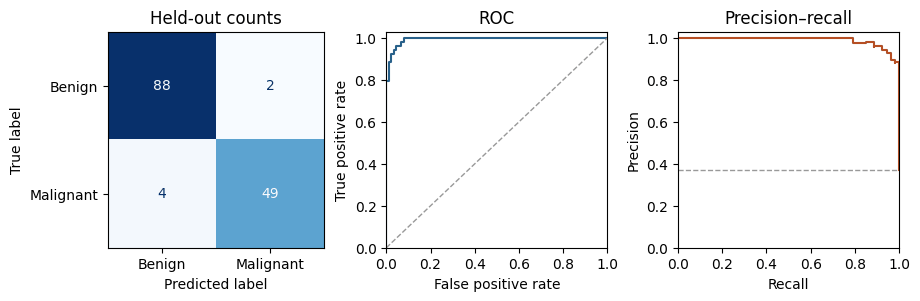

In [4]:
probability = classification_report(model, X, X_test, y, y_test)
plt.show()

## Reading the result

Compare the minority-class recall to the majority-prior baseline and inspect the number of errors behind it.

## References

[scikit-learn, RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)

[Wolberg, Mangasarian, Street and Street, Breast Cancer Wisconsin (Diagnostic), UCI, CC BY 4.0](https://doi.org/10.24432/C5DW2B)